In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Working with Sequences

An email client that sees "Thank you for your" proposes "help" or "time".
A weather service that has recorded the temperature every hour forecasts
the next hour. In both cases the best prediction depends on what came
before, and on its order: "your thank for you" calls for a different
continuation, and a falling temperature curve for a different forecast than
a rising one. The models of the earlier chapters cannot express this. They
map one input of fixed shape, a vector $\mathbf{x} \in \mathbb{R}^d$, to one
output, and they treat examples as independent. A sentence, a recording, or
a series of measurements has neither property: its length varies, and its
entries depend on each other.

This section turns sequence modeling into a problem we already know how to
solve, regression. We predict each entry from the entries before it, and we
keep the input of the predictor at a fixed size. Either we look only at a
window of recent entries, or we carry a running summary of everything seen
so far. We then fit a linear model on a fixed window to a noisy sine wave,
where we know the truth. Predicting one step ahead turns out to be easy.
Predicting many steps ahead, by feeding the model its own predictions, is
hard. The rest of the chapter applies the same ideas to text.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## Sequential Data

The email and the temperature record of the opening look different, but we
can describe both, and every other kind of sequence, in the same terms.
A *sequence* is an ordered list of feature vectors
$\mathbf{x}_1, \ldots, \mathbf{x}_T$, or of scalars $x_1, \ldots, x_T$.
The index $t \in \mathbb{Z}^+$ is a *time step*, and the length $T$ may
differ from one sequence to the next.
Text is a sequence of characters or words.
Audio, whether speech or music, is a sequence of samples,
or of the spectrogram frames computed from them.
Time series such as prices, sensor readings, and patient vitals
arrive one measurement at a time, each shaped by its recent past.

We still assume that *entire* sequences (a whole document,
a whole patient trajectory) are drawn independently
from one fixed distribution over sequences.
*Within* a sequence, however, the entries depend on each other:
the medicine a patient receives on day ten of a hospital stay
depends heavily on the previous nine days.
This dependence is what makes the past useful: if the entries were
independent, conditioning on earlier entries would not improve a
prediction of the next one.
We do not even assume that the entries share one distribution.
A document reads differently at its end than at its beginning,
and a patient's status evolves toward recovery or decline.

Prediction tasks over sequences come in a few shapes.
Sometimes the target is a single label for an entire input sequence
(the sentiment of a movie review),
sometimes a sequence given a fixed input (captioning an image),
and sometimes a sequence given a sequence
(translating a sentence, transcribing speech).
Before handling targets of any kind, we model the sequence itself:
we estimate how probable a given sequence is,
$P(x_1, \ldots, x_T)$.

## Autoregressive Models

Take a numerical series such as a stock index or a temperature reading.
A forecaster who wants to act on the next step
cares about the conditional distribution of that step given the
observations before it,

$$P(x_t \mid x_1, \ldots, x_{t-1}).$$

Even when the full distribution is hard to pin down,
a useful summary is the conditional expectation
$\mathbb{E}[x_t \mid x_1, \ldots, x_{t-1}]$,
which we could try to fit with linear regression
(that section).
A model that regresses a signal on its own past
is an *autoregressive model*: features and target
come from the same series.

There is an immediate obstacle.
The number of conditioning inputs $x_1, \ldots, x_{t-1}$
grows with $t$, so if we treat the history as a training set,
every example has a different number of features
and no fixed-input model applies.
Two strategies produce fixed-size representations of the history
(the figure).

### Fixed Windows

The first strategy conditions only on the last $m$ observations
$x_{t-m}, \ldots, x_{t-1}$ and discards older history.
Every example then has $m$ features (for $t > m$),
so any model with a fixed input length, linear or deep, applies.
This is *autoregression* in its narrow sense, and $m$ is the
*window length*.
The $n$-gram language models of that section use the same
idea for a stream of words.
A window is simple and easy to parallelize.
Its weakness is a hard horizon:
anything older than $m$ steps is invisible to the model.

### Latent Summaries

The second strategy keeps a running summary of the observations
$x_1, \ldots, x_t$, a vector $\mathbf{h}_t$, and updates it as each new
observation arrives, $\mathbf{h}_t = g(\mathbf{h}_{t-1}, x_t)$.
We predict the next entry from the summary,
$\hat{x}_{t+1} = f(\mathbf{h}_t)$.
Because $\mathbf{h}_t$ is never observed directly,
this is a *latent autoregressive model*.
The state $\mathbf{h}_t$ has the same size however long the history
grows, so a past of any length fits into bounded memory.
Recurrent neural networks (that section) are latent autoregressive
models with a learned $g$, and so are the state space models of
that section.
What the state should retain, and how to update it, are the questions of
those sections.

![Two ways to give a sequence model a fixed-size input. (left) Autoregression conditions on a sliding window of the last $m$ observations and discards the rest. (right) Latent autoregression carries a recurrent state $\mathbf{h}_t$ that summarizes the whole past in fixed size.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-ar-vs-latent.svg)

### From Conditionals to Sequences

Whichever strategy we pick, the one-step conditionals determine a model of
the whole sequence.
The *chain rule of probability* writes any joint distribution as a product
of conditionals, one factor per entry, each conditioned on all the entries
before it:

$$P(x_1, \ldots, x_T) = \prod_{t=1}^T P(x_t \mid x_1, \ldots, x_{t-1}).$$

The first factor has nothing to condition on and is $P(x_1)$.
The factorization is exact: it holds for every distribution over
sequences.
Thus a model of the next entry is a model of the entire sequence.
For three words,

$$P(\textrm{the}, \textrm{cat}, \textrm{sat}) =
P(\textrm{the})\, P(\textrm{cat} \mid \textrm{the})\,
P(\textrm{sat} \mid \textrm{the}, \textrm{cat}),$$

and a model that assigns $0.05$, $0.01$, and $0.2$ to the three factors
gives the sentence probability $10^{-4}$.
To score a sequence, we multiply its conditionals,
or add their logarithms, which avoids underflow for long sequences.
To generate a sequence, we sample $x_1$, then $x_2$ given $x_1$, and so
on, feeding each sample into the next condition.
When the entries are discrete tokens,
each conditional is a classifier over the vocabulary,
and estimating $P(x_1, \ldots, x_T)$ is called
*language modeling* (that section).
For now we keep the values continuous and focus on prediction.

## Markov Models and Stationarity

A fixed window assumes that the observations it discards do not matter.
Every autoregressive model also assumes that the rule linking an entry to
its predecessors is the same at all times. Both assumptions have names.

### The Markov Condition

When conditioning on the last $m$ steps loses no predictive power
relative to the full history, we say the sequence satisfies
a *Markov condition*: the future is conditionally independent
of the distant past given the recent past.
With $m = 1$ the series follows a *first-order* Markov model,
and in general an $m^{\textrm{th}}$-order one.
Under the first-order condition each factor of
the equation depends on its predecessor only,
and the factorization collapses to a product over adjacent pairs:

$$P(x_1, \ldots, x_T) = P(x_1) \prod_{t=2}^T P(x_t \mid x_{t-1}).$$

In practice the Markov condition rarely holds exactly.
Real text keeps yielding information as we widen the context,
though each additional token adds less than the one before.
We often assume an $m^{\textrm{th}}$-order condition anyway,
because it keeps the model small enough to compute and to estimate from data.
Even large language models read a context window of fixed length,
not everything that came before it.
For discrete data the simplest such model counts:
$P(x_t \mid x_{t-1})$ is estimated by the relative frequency
of each successor, an idea we take up again
for $n$-grams in that section.

### Stationarity

Fitting any of these models assumes that the *rule* generating
each entry from its predecessors does not itself change over time.
Dynamics with this property are called *stationary*.
The values still change, sometimes dramatically;
what stays fixed is the conditional distribution
$P(x_t \mid x_{t-m}, \ldots, x_{t-1})$.
Stationarity is what lets us pool examples from different parts
of one sequence, or from many sequences, into a single training set,
and it is why we build training data by sliding a window along a
series.

One choice above was implicit: we factored the sequence left to right.
Any order gives a valid factorization,
but for causal data the forward direction is usually easier to learn,
since predicting an effect from its cause tends to be simpler
than the reverse [@Peters.Janzing.Scholkopf.2017].
As we generally want to predict the future from the past anyway,
we factor left to right throughout.

## Forecasting a Noisy Sine Wave

We now fit an autoregressive model to data where we control the ground
truth, and compare predicting one step ahead with predicting many steps
ahead.

### Data and Model

The series has $T = 1000$ entries
$x_t = \sin(0.01\, t) + \epsilon_t$, where the noise $\epsilon_t$ is
drawn from $\mathcal{N}(0, 0.2^2)$ independently at every step.
One period of the sine spans $2\pi / 0.01 \approx 628$ steps.

In [2]:
class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, m=4):
        self.save_hyperparameters()
        self.time = d2l.arange(1, T + 1, dtype=d2l.float32)
        self.x = d2l.sin(0.01 * self.time) + d2l.randn(T) * 0.2

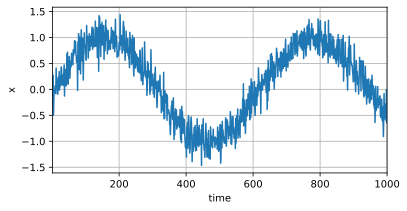

In [3]:
data = Data()
d2l.plot(data.time, data.x, 'time', 'x', xlim=[1, 1000], figsize=(6, 3))

To turn the series into supervised examples,
we adopt the fixed-window strategy with window length $m$:
the label is $y = x_t$ and the features are
$(x_{t-m}, \ldots, x_{t-1})$.
This yields $T - m$ examples,
since the first $m$ steps lack enough history and we drop them
(padding with zeros is the alternative).
The method `lag_features` builds all of them at once, one column per lag,
and the data loader serves the first 600 for training,
a bit less than one period of the sine.

In [4]:
@d2l.add_to_class(Data)
def lag_features(self):
    """Features (x_{t-m}, ..., x_{t-1}) and labels x_t for t > m."""
    features = [self.x[i : self.T-self.m+i] for i in range(self.m)]
    return d2l.stack(features, 1), d2l.reshape(self.x[self.m:], (-1, 1))

@d2l.add_to_class(Data)
def get_dataloader(self, train):
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader(self.lag_features(), train, i)

Our model is linear regression on the $m = 4$ lag features,
about the simplest autoregressive model there is.

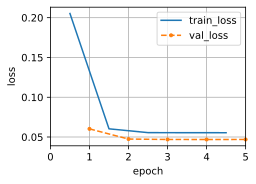

In [5]:
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=5)
trainer.fit(model, data)

### One-Step-Ahead Prediction

First the easy case: predict $\hat{x}_t$ from the *observed* previous
$m$ values, for every $t > m$.

In [6]:
features, labels = data.lag_features()
with torch.inference_mode():  # prediction only: record no gradients
    onestep_preds = d2l.numpy(model(features))

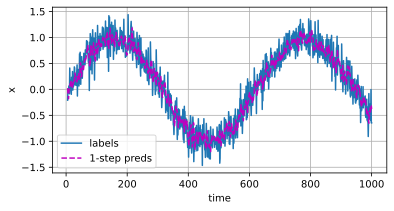

In [7]:
d2l.plot(data.time[data.m:], [labels, onestep_preds], 'time', 'x',
         legend=['labels', '1-step preds'], figsize=(6, 3))

The predictions track the series closely, also beyond step 600,
where the model sees data it was not trained on.

### Multistep Rollout

The hard case is forecasting several steps ahead.
Suppose we have observed only up to step 604
(the 600 training examples need the first 604 observations)
and want to predict $\hat{x}_{609}$.
We cannot form the one-step input for step 609,
because we have not observed $x_{605}, \ldots, x_{608}$.
The fix is to feed our own predictions back in
as if they were observations, rolling forward one step at a time:

$$
\begin{aligned}
\hat{x}_{605} &= f(x_{601}, x_{602}, x_{603}, x_{604}), \\
\hat{x}_{606} &= f(x_{602}, x_{603}, x_{604}, \hat{x}_{605}), \\
\hat{x}_{607} &= f(x_{603}, x_{604}, \hat{x}_{605}, \hat{x}_{606}),\\
\hat{x}_{608} &= f(x_{604}, \hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}),\\
\hat{x}_{609} &= f(\hat{x}_{605}, \hat{x}_{606}, \hat{x}_{607}, \hat{x}_{608}).
\end{aligned}
$$

From step 609 on, the model sees only its own predictions.
For an observed series $x_1, \ldots, x_t$,
the prediction $\hat{x}_{t+k}$ is the *$k$-step-ahead prediction*,
and a *rollout* chains one-step predictions to reach it.
The loop below rolls forward from step 604 to the end of the series.

In [8]:
multistep_preds = data.x.clone()
with torch.inference_mode():
    for i in range(data.num_train + data.m, data.T):
        multistep_preds[i] = model(
            multistep_preds[i-data.m : i].reshape(1, -1))
multistep_preds = d2l.numpy(multistep_preds)

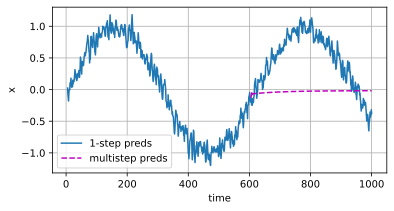

In [9]:
start = data.num_train + data.m
d2l.plot([data.time[data.m:], data.time[start:]],
         [onestep_preds, multistep_preds[start:]], 'time', 'x',
         legend=['1-step preds', 'multistep preds'], figsize=(6, 3))

The rollout never follows the oscillation.
It starts at the level of the last observed window and drifts slowly
toward a constant, while the series rises and falls.
The learned weights show why.

In [10]:
w, b = model.get_w_b()
print(f'weights on x[t-{data.m}], ..., x[t-1]:',
      d2l.numpy(d2l.reshape(w, -1)).round(3))

weights on x[t-4], ..., x[t-1]: [0.221 0.244 0.251 0.26 ]


All four weights are close to $1/4$:
the model has learned to predict the next value as the average of the
last four.
For one step this is a sound rule.
The sine changes by at most $0.01$ from one step to the next,
while the noise has a standard deviation of $0.2$.
An average of four noisy observations carries only a quarter of their
noise variance, $0.04/4 = 0.01$, and lagging the curve by a step or two
adds almost no error.
Fed its own outputs, however, an average of the last four values can
only repeat their current level.
Because the weights sum to slightly less than one, that level also
drifts slowly toward the rollout's fixed point $b / (1 - \sum_i w_i)$,
where $b$ is the bias: a small bias divided by a small difference, so the
fixed point differs from run to run.
The model has not learned the curvature of the sine, which the one-step
loss barely rewarded, and over many steps that omission dominates the
error.
A linear model *could* continue a sine wave far better;
exercise 1 asks how.

### Error Growth with the Horizon

How fast does the error grow with the horizon $k$?
To find out, we compute $k$-step-ahead predictions from every start
position at once.
`k_step_pred` keeps a list of columns, each with one entry per start
position.
The first $m$ columns hold the observed lags; each round appends the
predictions made from the last $m$ columns, so entry $j-1$ of the
returned list holds the $j$-step-ahead predictions.

In [11]:
def k_step_pred(model, x, m, k):
    """Predictions 1, 2, ..., k steps ahead from every start position."""
    n = len(x) - m - k + 1                       # number of start positions
    columns = [x[i : i + n] for i in range(m)]   # observed lags
    for j in range(k):
        preds = model(d2l.stack(columns[j : j + m], 1))
        columns.append(d2l.reshape(preds, -1))
    return columns[m:]                           # entry j-1: j steps ahead

In [12]:
steps = (1, 4, 16, 64)
with torch.inference_mode():
    preds = k_step_pred(model, data.x, data.m, steps[-1])

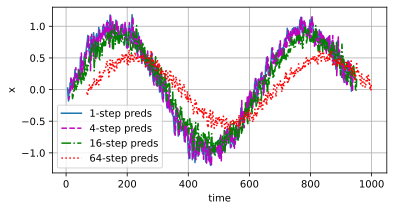

In [13]:
d2l.plot([data.time[data.m+k-1 : data.T-steps[-1]+k] for k in steps],
         [d2l.numpy(preds[k-1]) for k in steps], 'time', 'x',
         legend=[f'{k}-step preds' for k in steps], figsize=(6, 3))

The 1- and 4-step forecasts follow the series.
The 16-step forecast lags it visibly, and the 64-step forecast is a copy
of the series delayed by about 64 steps and visibly shrunk in amplitude;
how much it shrinks depends on how far the weights' sum falls short of
one.
The mean squared error against the observed values puts numbers on this.
As a reference, the variance of the series is the mean squared error of a
forecast that always predicts the mean.

In [14]:
x = d2l.numpy(data.x)
for k in steps:
    err = d2l.numpy(preds[k-1]) - x[data.m+k-1 : data.T-steps[-1]+k]
    print(f'{k:2d} steps ahead: mean squared error {(err**2).mean():.3f}')
print(f'variance of the series: {x.var():.3f}')

 1 steps ahead: mean squared error 0.052
 4 steps ahead: mean squared error 0.060
16 steps ahead: mean squared error 0.074
64 steps ahead: mean squared error 0.268
variance of the series: 0.485


One step ahead, the error is about $0.05$: the noise variance
$0.2^2 = 0.04$, which no forecast can remove, plus the $0.01$ of noise
left in an average of four observations.
The growth with $k$ follows from the delay.
A $k$-step forecast is roughly the series $k$ steps earlier, so its
additional error is how far the sine moves in $k$ steps.
Averaged over the phase $a$ of the sine, that squared change is

$$\frac{1}{2\pi}\int_0^{2\pi} \bigl(\sin(a + 0.01\,k) - \sin a\bigr)^2 \, da
= 1 - \cos(0.01\,k),$$

which is $0.001$ for $k = 4$, $0.013$ for $k = 16$, and $0.20$ for
$k = 64$.
Added to the floor of $0.05$, it predicts errors of about $0.05$, $0.05$,
$0.065$, and $0.25$, close to the measured ones.
Sixty-four steps ahead, the error is four to six times the one-step
error and roughly half the variance of the series.

The averaging model damps whatever is fed back into it, so its rollout
drifts toward a constant instead of diverging.
The underlying problem is general, though: in a rollout every prediction
error becomes part of the input of all later steps, and nothing corrects
it.
A model that amplifies its errors instead of damping them drifts away from
the data altogether.

The same problem affects every autoregressive generator that consumes its
own outputs.
A language model that samples one token at a time can drift
off topic or into repetition once a few unusual choices
steer it into text unlike anything it saw during training.
A learned simulator of a physical system loses coherence
over a long rollout for the same reason.
Two remedies exist.
First, the rule that turns each predicted distribution into a concrete
next value matters: that section compares such rules for
text.
Second, exposing a model to its own predictions during training,
not only to observed histories,
narrows the gap between the one-step setting it is trained in
and the multistep setting it is used in
(exercise 7).

## Summary

A sequence is an ordered list whose entries depend on each other, and
whose length varies.
Autoregressive models turn sequence modeling into ordinary
supervised learning by predicting each entry from its predecessors,
either through a fixed window of the last $m$ observations
(autoregression, the idea behind $n$-grams) or through a latent state
that summarizes the whole past in bounded memory
(latent autoregression, the idea behind recurrent networks).
By the chain rule of probability, the one-step conditionals multiply to a
model of the whole sequence, which can score and generate sequences.
Fitting one model to all positions of a series assumes that the rule
generating each entry does not change over time (stationarity).
One-step-ahead prediction is comparatively easy.
Multistep forecasting feeds predictions back as inputs,
so it can never correct its errors. On the noisy sine wave, the
averaging model carries the last observed level forward, and its error
64 steps ahead is four to six times the one-step error.

## Exercises

1. [code] **Window length.** `Data` supplies `m=4` lag features and
   `d2l.LinearRegression` fits them.
    1. Increase `m` and retrain. How many past observations are needed
       before the validation error stops improving?
    1. Suppose the noise term in `Data` were removed. How many past
       observations then suffice for exact prediction, and why?

1. **Momentum strategies.** An investor selects stocks by their own past
   returns, expecting those that rose to keep rising. State the assumption
   about the return series that this strategy requires, in the terms of
   that section and that section, and
   describe one mechanism by which the assumption fails.

1. [code] **Nonlinear autoregressor.** Replace `d2l.LinearRegression` by a
   small MLP on the same four lag features and retrain, possibly for more
   epochs. How do the one-step and the multistep predictions change?

1. [code] **Error growth with the horizon.** For each $k$, the last entry
   of the list that `k_step_pred(model, data.x, data.m, k)` returns holds
   the $k$-step-ahead predictions of `data.x[data.m+k-1:]`.
    1. For $k \in \{1, 2, 4, \ldots, 256\}$, plot the mean squared
       $k$-step error against $k$ on a logarithmic axis. Where does the
       curve bend upward, and how does the bend relate to the damping of
       the 16-step and 64-step forecasts?
    1. Find the smallest $k$ at which the mean squared $k$-step error
       exceeds the variance of the series. What does a forecast beyond
       this horizon offer over the constant forecast?

1. [code] **Dilated and averaged lags.** ● Keep four features for
   `d2l.LinearRegression` but let them reach further back: once as the
   lags $x_{t-1}, x_{t-2}, x_{t-4}, x_{t-8}$, and once as the four block
   means $\frac{1}{4}\sum_{i=0}^{3} x_{t-4j+i}$ for $j = 1, \ldots, 4$.
   Compare their validation errors with those for $m = 4$ and
   $m = 16$. Which construction helps, and why?

1. [code] **Regime switching.** ● Replace the single sine in `Data` by a
   series that alternates between $\sin(0.01\,t)$ and $\sin(0.05\,t)$
   every 200 time steps, and keep the additive noise. Both regimes then
   occur among the training examples and among the validation examples.
   The switching series violates the stationarity assumption
   of that section. Does one linear model with $m = 4$
   nevertheless fit both regimes, and why? Report training and validation
   error for each regime separately and locate the positions along the
   series where the fit is worst.

1. [code] **Scheduled sampling.** ● that section
   states that exposing a model to its own predictions during training
   narrows the gap between one-step training and multistep use. Test the
   claim with a variant of *scheduled sampling*
   [@Bengio.Vinyals.Jaitly.ea.2015] for the linear model with
   $m = 4$. In every minibatch, replace each lag feature with
   probability $\epsilon$ by the model's current one-step prediction of
   that observation. Train one model for each
   $\epsilon \in \{0, 0.25, 0.5, 1\}$. For each model, measure the
   one-step validation error and the mean squared error of the last entry
   of `k_step_pred(model, data.x, data.m, 64)`. Does any $\epsilon > 0$
   lower the 64-step error below its value at $\epsilon = 0$? How does the
   one-step error change?

[Discussions](https://d2l.discourse.group/t/114)